# Automated SLiM Modelling with CALVADOS

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from tqdm import tqdm
import sys
import os
import mdtraj as md

sys.path.append('..')
from src import visualisation as vis

## First test

In [28]:
# Loading trajectory
pdb_path = "../data/calvados/single_slim_example/s_scan/sh3-prm_5.0/top.pdb"
dcd_path = "../data/calvados/single_slim_example/s_scan/sh3-prm_5.0/sh3-prm_5.0.dcd"

traj = md.load(dcd_path, top=pdb_path)
n_frames = len(traj)
dt = 0.1 # ns
time = np.arange(0,n_frames*dt, step=dt)

In [29]:
# Loading SLiM contacts
def parse_fspecific_interactions(path):
    spec = []
    with open(path,'r') as f:
        for line in f.readlines():
            line = line.strip()
            if (not line) or line.startswith('#'):
                continue
            left, right, params = line.split('|')
            name_i, bead_i = left.split()
            name_j, bead_j = right.split()
            s, k = params.split()
            spec.append([name_i, int(bead_i), name_j, int(bead_j), float(s), float(k)]) # 1-based
    return np.array(spec)

fspecific_interactions = parse_fspecific_interactions("../data/calvados/single_slim_example/s_scan/input/specific_interactions.txt")

In [30]:
# Determining residue IDs per chain
slim_indices = fspecific_interactions[:,(3,1)].astype(int) - 1 # PRM, SH3
slim_eqdists = fspecific_interactions[:,4].astype(float)

# Converting residue IDs to residue indices in MD topology
prm_resids = traj.topology.select('chainid 0')
sh3_resids = traj.topology.select('chainid 1')
slim_resiuds = np.vstack((prm_resids[slim_indices[:,0]], sh3_resids[slim_indices[:,1]])).T

In [31]:
# Calculating distance between slim contacts
slim_dists = md.compute_distances(traj, slim_resiuds, periodic=True)

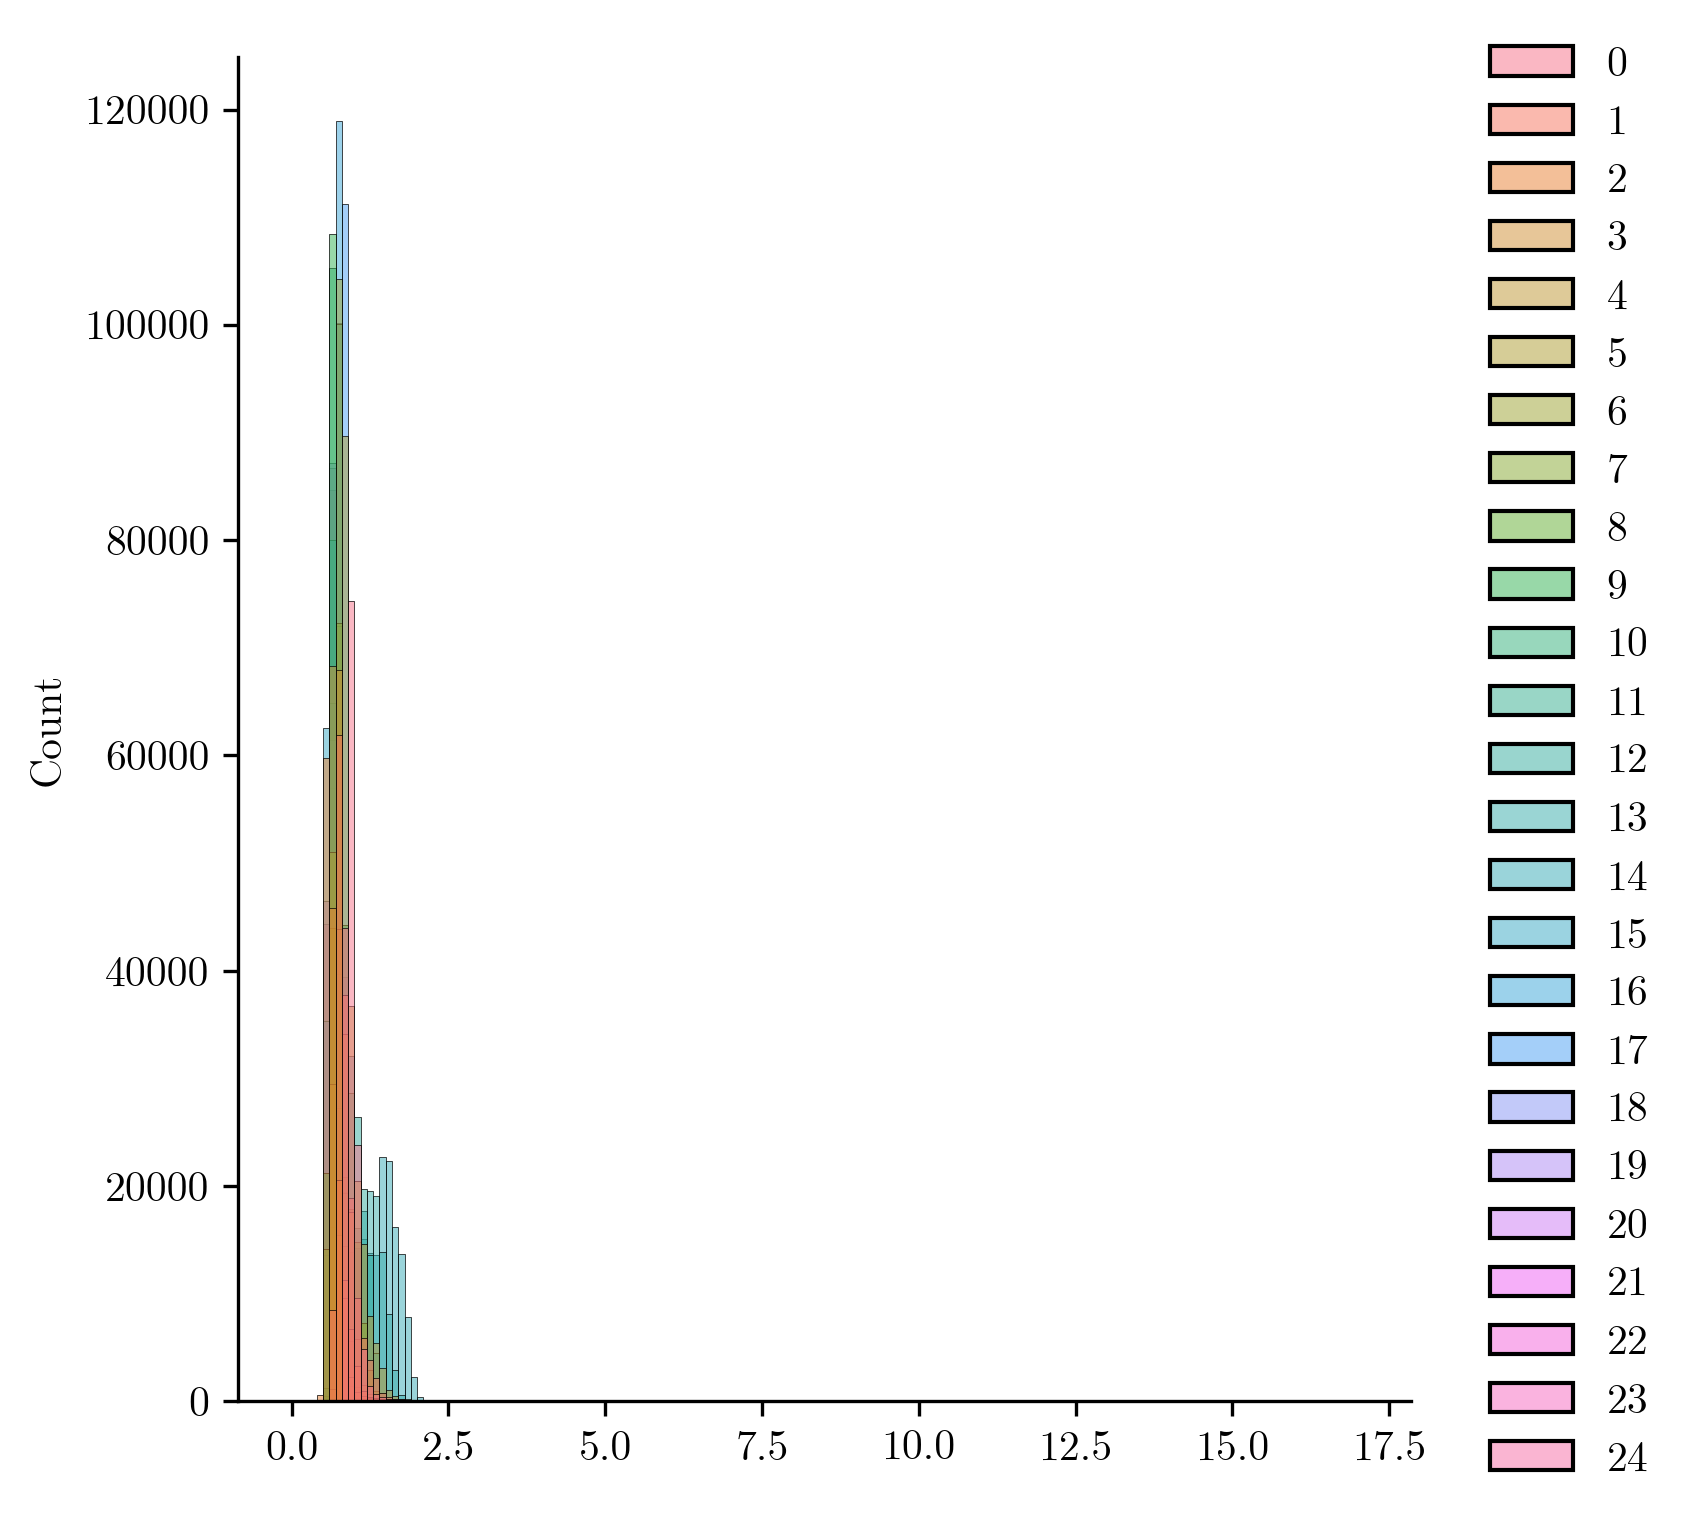

In [40]:
sns.displot(slim_dists, bins=np.linspace(0,17,171))

In [33]:
@np.vectorize
def calc_Kd(fraction_bound, concentration):
    fc = fraction_bound
    Pt = concentration
    Lt = Pt
    if fc <= 0.0: return 0
    if fc >= 1.0: return np.inf
    Kd = Pt * fc + Lt / fc - Pt - Lt
    return Kd

box_volume = traj.unitcell_volumes[0] * 1e-24 # L
N_A = 6.02e23
chains = 1
chain_concentration = 1e6 * (chains) / (N_A * box_volume) # µM

fraction_bound = (slim_dists <= 2).mean()

calc_Kd(fraction_bound, chain_concentration) # µM

array(0.00018773)

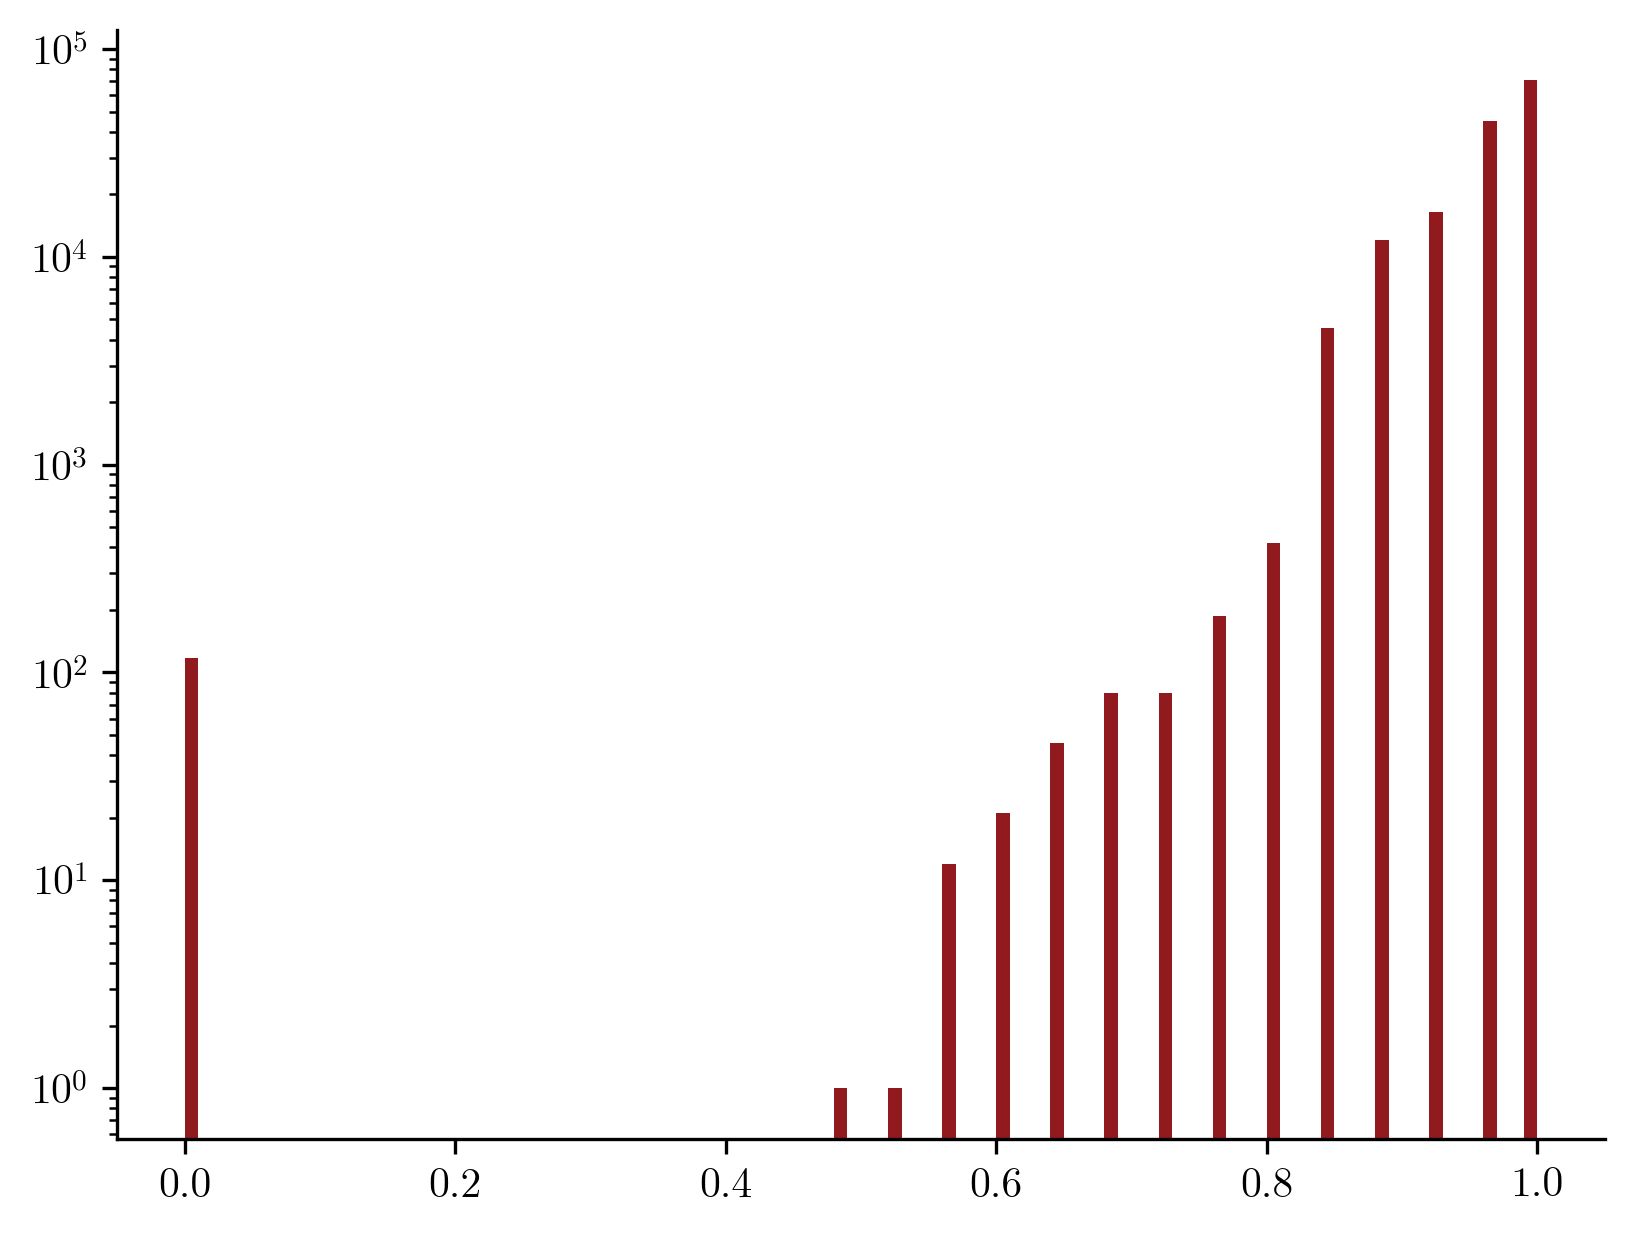

In [39]:
plt.hist((slim_dists <= slim_eqdists*2).mean(axis=1), bins=np.linspace(0,1,101))
plt.yscale('log')